In [1]:
import pandas as pd

data = {
    'start_hour': [0.0, 1.0, 2.0, 3.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0],
    'count_trip_weekend': [8, 3, 2, 1, 2, 1, 4, 4, 17, 14, 12, 18, 13, 26, 27, 19, 27, 29, 21, 15, 17, 8, 5],
    'count_trip_weekday': [11, 2, 0, 2, 2, 3, 9, 31, 34, 51, 60, 59, 81, 63, 71, 69, 68, 65, 47, 56, 33, 22, 9]
}

df = pd.DataFrame(data)
print(df)

    start_hour  count_trip_weekend  count_trip_weekday
0          0.0                   8                  11
1          1.0                   3                   2
2          2.0                   2                   0
3          3.0                   1                   2
4          5.0                   2                   2
5          6.0                   1                   3
6          7.0                   4                   9
7          8.0                   4                  31
8          9.0                  17                  34
9         10.0                  14                  51
10        11.0                  12                  60
11        12.0                  18                  59
12        13.0                  13                  81
13        14.0                  26                  63
14        15.0                  27                  71
15        16.0                  19                  69
16        17.0                  27                  68
17        

In [2]:
df['start_hour_formatted'] = df['start_hour'].apply(lambda x: f'{int(x):02d}:00')
df

,start_hour,count_trip_weekend,count_trip_weekday,start_hour_formatted
0,0.0,8,11,00:00
1,1.0,3,2,01:00
2,2.0,2,0,02:00
3,3.0,1,2,03:00
4,5.0,2,2,05:00
5,6.0,1,3,06:00
6,7.0,4,9,07:00
7,8.0,4,31,08:00
8,9.0,17,34,09:00
9,10.0,14,51,10:00


In [3]:
max_weekday_idx = df['count_trip_weekday'].idxmax()
peak_weekday_hour = df.loc[max_weekday_idx, 'start_hour_formatted']
peak_weekday_val = df.loc[max_weekday_idx, 'count_trip_weekday']

max_weekend_idx = df['count_trip_weekend'].idxmax()
peak_weekend_hour = df.loc[max_weekend_idx, 'start_hour_formatted']
peak_weekend_val = df.loc[max_weekend_idx, 'count_trip_weekend']

In [4]:
import matplotlib.pyplot as plt

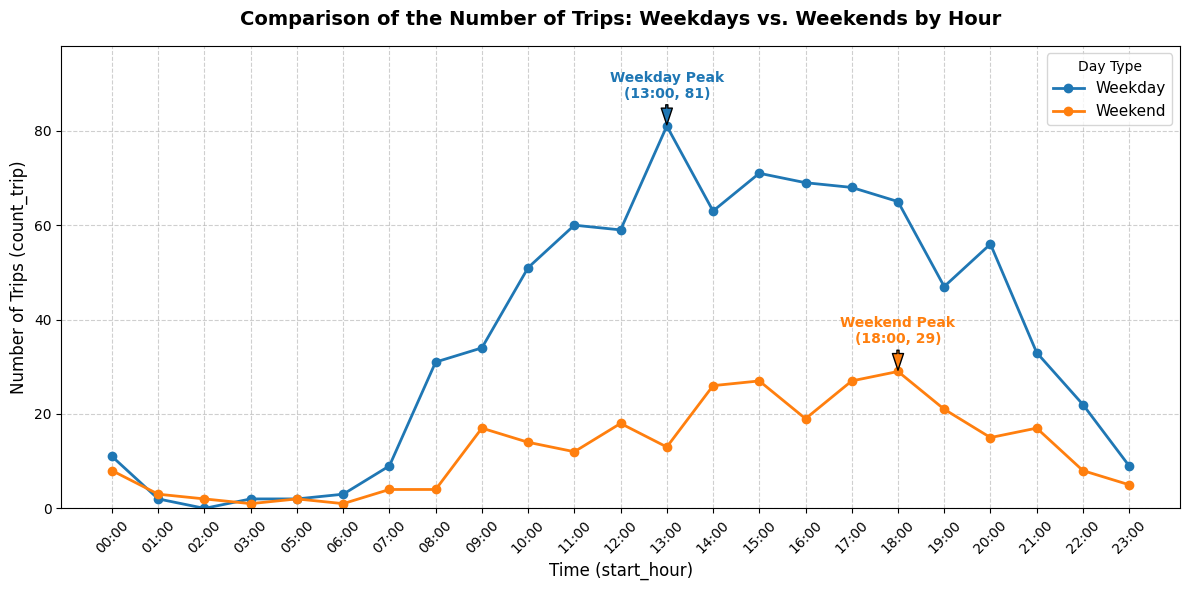

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    df['start_hour_formatted'],
    df['count_trip_weekday'],
    marker='o',
    label='Weekday',
    color='tab:blue',
    linewidth=2,
)
plt.plot(
    df['start_hour_formatted'],
    df['count_trip_weekend'],
    marker='o',
    label='Weekend',
    color='tab:orange',
    linewidth=2,
)

# Menandai Puncak Weekday
plt.annotate(
    f'Weekday Peak\n({peak_weekday_hour}, {peak_weekday_val})',
    xy=(peak_weekday_hour, peak_weekday_val),
    xytext=(peak_weekday_hour, peak_weekday_val + 6),
    arrowprops=dict(
        facecolor='tab:blue', shrink=0.05, width=1.5, headwidth=8
    ),
    ha='center',
    fontweight='bold',
    color='tab:blue',
)

# Menandai Puncak Weekend
plt.annotate(
    f'Weekend Peak\n({peak_weekend_hour}, {peak_weekend_val})',
    xy=(peak_weekend_hour, peak_weekend_val),
    xytext=(peak_weekend_hour, peak_weekend_val + 6),
    arrowprops=dict(
        facecolor='tab:orange', shrink=0.05, width=1.5, headwidth=8
    ),
    ha='center',
    fontweight='bold',
    color='tab:orange',
)

# Pengaturan Tata Letak Grafis
plt.ylim(0, 98)
plt.title(
    'Comparison of the Number of Trips: Weekdays vs. Weekends by Hour',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Time (start_hour)', fontsize=12)
plt.ylabel('Number of Trips (count_trip)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Day Type', fontsize=11)
plt.tight_layout()

plt.show()